# Global Solution MLAM — Mobilidade urbana e bicicletas compartilhadas

**Problema:** investigar como clima e horário se relacionam com a demanda por bicicletas compartilhadas.

**Base principal:** `dataset/hour.csv` (17.379 registros). Base complementar: `dataset/day.csv` (731 registros).



In [4]:
# Dependências: pip install pandas numpy matplotlib scipy statsmodels scikit-learn jupyter
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
pd.set_option("display.max_columns", None)


In [5]:
DATA_DIR=Path("/content/dataset") if Path("/content/dataset/hour.csv").exists() else Path("dataset")
hour=pd.read_csv(DATA_DIR/"hour.csv")
day=pd.read_csv(DATA_DIR/"day.csv")
df=hour.copy()
df["dteday"]=pd.to_datetime(df["dteday"])
print("Base horária:",df.shape,"| Base diária:",day.shape)
display(df.head())
display(df.describe().T)
print("Ausentes:",df.isna().sum().sum(),"| Duplicados:",df.duplicated().sum())


Base horária: (17379, 17) | Base diária: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045568,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


Ausentes: 0 | Duplicados: 0


## 1. Contextualização e preparação

A variável principal é `cnt`, total de bicicletas alugadas por hora. `casual` e `registered` não serão preditoras porque sua soma corresponde a `cnt`, o que causaria vazamento de informação. As variáveis climáticas `temp`, `hum` e `windspeed` são normalizadas na base original.


## 2. Distribuição Normal de probabilidade

Assumindo `cnt ~ Normal(μ, σ)`, calculamos P(X < média) e P(X > mediana empírica). A classificação verbal deve seguir as faixas definidas pelo professor.


In [6]:
x=df["cnt"].astype(float); mu=x.mean(); sigma=x.std(ddof=0); mediana=x.median()
p_menor_media=stats.norm.cdf(mu,loc=mu,scale=sigma)
p_maior_mediana=1-stats.norm.cdf(mediana,loc=mu,scale=sigma)
print(f"Média={mu:.2f}; desvio padrão populacional={sigma:.2f}; mediana={mediana:.2f}")
print(f"P(X < média)={p_menor_media:.4%}")
print(f"P(X > mediana)={p_maior_mediana:.4%}")


Média=189.46; desvio padrão populacional=181.38; mediana=142.00
P(X < média)=50.0000%
P(X > mediana)=60.3214%


## 3. Testes de hipóteses para a média

Teste Z unilateral, usando σ populacional da base, conforme o enunciado. A média de referência μ0 é a média de `cnt` na base. Amostras aleatórias sem reposição, semente fixa 42.

- A: H0: μ=μ0; H1: μ<μ0; α=6%; n=20.
- B: H0: μ=μ0; H1: μ>μ0; α=9%; n=25.


In [7]:
rng=np.random.default_rng(42); pop=df["cnt"].to_numpy(dtype=float)
mu0=pop.mean(); sigma_pop=pop.std(ddof=0)
amostra20=rng.choice(pop,size=20,replace=False)
z_a=(amostra20.mean()-mu0)/(sigma_pop/np.sqrt(20)); p_a=stats.norm.cdf(z_a)
print(f"Teste A: média amostral={amostra20.mean():.2f}; z={z_a:.4f}; p={p_a:.6f}; decisão={'rejeitar H0' if p_a<.06 else 'não rejeitar H0'}")
amostra25=rng.choice(pop,size=25,replace=False)
z_b=(amostra25.mean()-mu0)/(sigma_pop/np.sqrt(25)); p_b=1-stats.norm.cdf(z_b)
print(f"Teste B: média amostral={amostra25.mean():.2f}; z={z_b:.4f}; p={p_b:.6f}; decisão={'rejeitar H0' if p_b<.09 else 'não rejeitar H0'}")


Teste A: média amostral=179.15; z=-0.2543; p=0.399640; decisão=não rejeitar H0
Teste B: média amostral=177.84; z=-0.3204; p=0.625669; decisão=não rejeitar H0


## 4. Análise bivariada: temperatura × aluguéis

Inclui dispersão, covariância, correlação de Pearson, regressão simples, R², teste F e previsão na mediana da temperatura.


Covariância=14.138; Pearson r=0.4048; p=0
R²=0.1638; F=3404.923; p(F)=0


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       0.164
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     3405.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:19:31   Log-Likelihood:            -1.1349e+05
No. Observations:               17379   AIC:                         2.270e+05
Df Residuals:                   17377   BIC:                         2.270e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0356      3.483     -0.010      0.992      -6.862       6.791
temp         381.2949      6.534     58.352      0.000     368.487     394.103
==============================================================================
Omnibus:                     3140.760   Durbin-Watson:                   0.368
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5634.907
Skew:                           1.152   Prob(JB):                         0.00
Kurtosis:                       4.572   Cond. No.                         6.52
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

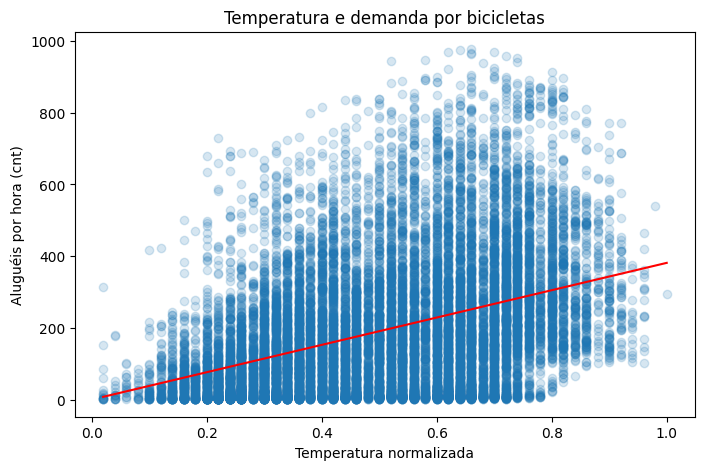

Previsão para temp mediana: 190.6118650169463


In [8]:
r,p=stats.pearsonr(df["temp"],df["cnt"])
cov=df[["temp","cnt"]].cov().iloc[0,1]
modelo_simples=ols("cnt ~ temp",data=df).fit()
print(f"Covariância={cov:.3f}; Pearson r={r:.4f}; p={p:.5g}")
print(f"R²={modelo_simples.rsquared:.4f}; F={modelo_simples.fvalue:.3f}; p(F)={modelo_simples.f_pvalue:.5g}")
display(modelo_simples.summary())
plt.figure(figsize=(8,5)); plt.scatter(df.temp,df.cnt,alpha=.18)
xx=np.linspace(df.temp.min(),df.temp.max(),100)
plt.plot(xx,modelo_simples.params['Intercept']+modelo_simples.params['temp']*xx,color='red')
plt.title("Temperatura e demanda por bicicletas"); plt.xlabel("Temperatura normalizada"); plt.ylabel("Aluguéis por hora (cnt)"); plt.show()
temp_exemplo=df.temp.median()
print("Previsão para temp mediana:",modelo_simples.predict(pd.DataFrame({"temp":[temp_exemplo]})).iloc[0])


## 5. Regressão linear múltipla

Modelo: `cnt ~ temp + hum + windspeed + hr`. A previsão é ilustrativa para temp=0,50, hum=0,60, windspeed=0,20 e hr=17.


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    cnt   R-squared:                       0.325
Model:                            OLS   Adj. R-squared:                  0.325
Method:                 Least Squares   F-statistic:                     2092.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:19:32   Log-Likelihood:            -1.1163e+05
No. Observations:               17379   AIC:                         2.233e+05
Df Residuals:                   17374   BIC:                         2.233e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     69.3765      6.363     10.903      0.000      56.904      81.848
temp         329.7945      5.940     55.524      0.000     318.152     341.437
hum         -206.8831      6.330    -32.680      0.000    -219.291    -194.475
windspeed     -2.4646      9.689     -0.254      0.799     -21.456      16.527
hr             7.4839      0.172     43.548      0.000       7.147       7.821
==============================================================================
Omnibus:                     4358.712   Durbin-Watson:                   0.498
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            10275.528
Skew:                           1.408   Prob(JB):                         0.00
Kurtosis:                       5.503   Cond. No.                         130.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

R²=0.3250; R² ajustado=0.3249; F=2091.632; p(F)=0


,temp,hum,windspeed,hr,cnt
temp,0.037078,-0.002596,-0.000545,0.183207,14.137600
hum,-0.002596,0.037222,-0.006847,-0.368847,-11.300287
windspeed,-0.000545,-0.006847,0.014967,0.116102,2.068951
hr,0.183207,-0.368847,0.116102,47.808998,494.239483
cnt,14.137600,-11.300287,2.068951,494.239483,32901.461104


,temp,hum,windspeed,hr,cnt
temp,1.000000,-0.069881,-0.023125,0.137603,0.404772
hum,-0.069881,1.000000,-0.290105,-0.276498,-0.322911
windspeed,-0.023125,-0.290105,1.000000,0.137252,0.093234
hr,0.137603,-0.276498,0.137252,1.000000,0.394071
cnt,0.404772,-0.322911,0.093234,0.394071,1.000000


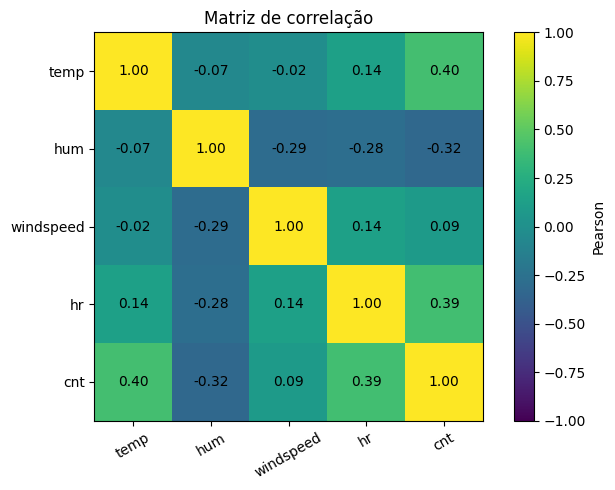

Previsão do cenário: 236.8769487110721


In [9]:
modelo_multiplo=ols("cnt ~ temp + hum + windspeed + hr",data=df).fit()
display(modelo_multiplo.summary())
print(f"R²={modelo_multiplo.rsquared:.4f}; R² ajustado={modelo_multiplo.rsquared_adj:.4f}; F={modelo_multiplo.fvalue:.3f}; p(F)={modelo_multiplo.f_pvalue:.5g}")
display(df[["temp","hum","windspeed","hr","cnt"]].cov())
corr=df[["temp","hum","windspeed","hr","cnt"]].corr()
display(corr)
plt.figure(figsize=(7,5)); plt.imshow(corr,vmin=-1,vmax=1); plt.colorbar(label="Pearson")
plt.xticks(range(len(corr)),corr.columns,rotation=30); plt.yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
 for j in range(len(corr)): plt.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center")
plt.title("Matriz de correlação"); plt.tight_layout(); plt.show()
cenario=pd.DataFrame({"temp":[.5],"hum":[.6],"windspeed":[.2],"hr":[17]})
print("Previsão do cenário:",modelo_multiplo.predict(cenario).iloc[0])


## 6. Regressão logística binária

Demanda alta = `cnt` acima da mediana; demanda baixa = `cnt` menor ou igual à mediana. Preditores: `temp`, `hum`, `windspeed` e `hr`. Excluímos `casual` e `registered` para evitar vazamento. Divisão treino/teste 75%/25%, estratificada e com semente 42. A equação é apresentada no espaço padronizado.


In [10]:
df["demanda_alta"]=(df["cnt"]>df["cnt"].median()).astype(int)
features=["temp","hum","windspeed","hr"]; X=df[features]; y=df["demanda_alta"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
modelo_logistico=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42))
modelo_logistico.fit(X_train,y_train); y_pred=modelo_logistico.predict(X_test)
matriz=confusion_matrix(y_test,y_pred); acuracia=accuracy_score(y_test,y_pred)
print("Matriz de confusão (linhas=real; colunas=previsto):\n",matriz)
print(f"Acurácia={acuracia:.2%}")
print(classification_report(y_test,y_pred,target_names=["Demanda baixa","Demanda alta"]))
reg=modelo_logistico.named_steps["logisticregression"]
print("logit(p) =",reg.intercept_[0],"+",dict(zip(features,reg.coef_[0])))


Matriz de confusão (linhas=real; colunas=previsto):
 [[1653  524]
 [ 515 1653]]
Acurácia=76.09%
               precision    recall  f1-score   support

Demanda baixa       0.76      0.76      0.76      2177
 Demanda alta       0.76      0.76      0.76      2168

     accuracy                           0.76      4345
    macro avg       0.76      0.76      0.76      4345
 weighted avg       0.76      0.76      0.76      4345

logit(p) = 0.012040573498696196 + {'temp': np.float64(1.0341438695742216), 'hum': np.float64(-0.6105209662110559), 'windspeed': np.float64(-0.029017044324201973), 'hr': np.float64(0.8626823136601094)}


## 7. Conclusões e limitações

Os modelos identificam associações estatísticas entre clima, horário e demanda. Correlação e regressão não comprovam causalidade. A hipótese Normal é uma simplificação didática. A base é histórica (Washington, D.C., 2011–2012), portanto não deve ser generalizada automaticamente para outras cidades ou períodos. Para aplicação real, recomenda-se atualizar os dados e realizar validação temporal.
